In [31]:
from pathlib import Path
import json
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

BASE_DIR = Path(r"C:\Users\praja\functional-connectivity")

PARTICIPANT = "sub-NDARINVYT858CBN"

FMRI_FILE = (
    BASE_DIR / "data" / "raw" /
    PARTICIPANT / "func" /
    f"{PARTICIPANT}_task-restAP_run-01_bold.nii.gz"
)

OUTPUT_DIR = BASE_DIR / "milestone_2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("MRI file exists:", FMRI_FILE.exists())
print("Output directory:", OUTPUT_DIR)

MRI file exists: True
Output directory: C:\Users\praja\functional-connectivity\milestone_2


In [33]:
fmri_img = nib.load(str(FMRI_FILE))

fmri_data = fmri_img.get_fdata(dtype=np.float32)

print("MRI dimensions:", fmri_data.shape)
print("Data type:", fmri_data.dtype)
print("Number of volumes:", fmri_data.shape[3])

MRI dimensions: (104, 104, 72, 488)
Data type: float32
Number of volumes: 488


In [35]:
print("Minimum:", np.nanmin(fmri_data))
print("Maximum:", np.nanmax(fmri_data))
print("Mean:", np.nanmean(fmri_data))
print("Standard deviation:", np.nanstd(fmri_data))

print("NaN values:", np.isnan(fmri_data).sum())
print("Infinite values:", np.isinf(fmri_data).sum())

print("All values finite:", np.isfinite(fmri_data).all())

Minimum: 0.0
Maximum: 29120.0
Mean: 1786.6313
Standard deviation: 2783.9458
NaN values: 0
Infinite values: 0
All values finite: True


In [37]:
metadata = {
    "dataset": "ds005237",
    "participant": PARTICIPANT,
    "task": "restAP",
    "dimensions": [int(x) for x in fmri_img.shape],
    "voxel_sizes": [
        float(x) for x in fmri_img.header.get_zooms()
    ],
    "orientation": list(nib.aff2axcodes(fmri_img.affine)),
    "repetition_time_seconds": float(
        fmri_img.header.get_zooms()[3]
    ),
    "sidecar_json_available": False
}

with open(OUTPUT_DIR / "preliminary_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print(json.dumps(metadata, indent=4))

{
    "dataset": "ds005237",
    "participant": "sub-NDARINVYT858CBN",
    "task": "restAP",
    "dimensions": [
        104,
        104,
        72,
        488
    ],
    "voxel_sizes": [
        2.0,
        2.0,
        2.0,
        0.800000011920929
    ],
    "orientation": [
        "L",
        "A",
        "S"
    ],
    "repetition_time_seconds": 0.800000011920929,
    "sidecar_json_available": false
}


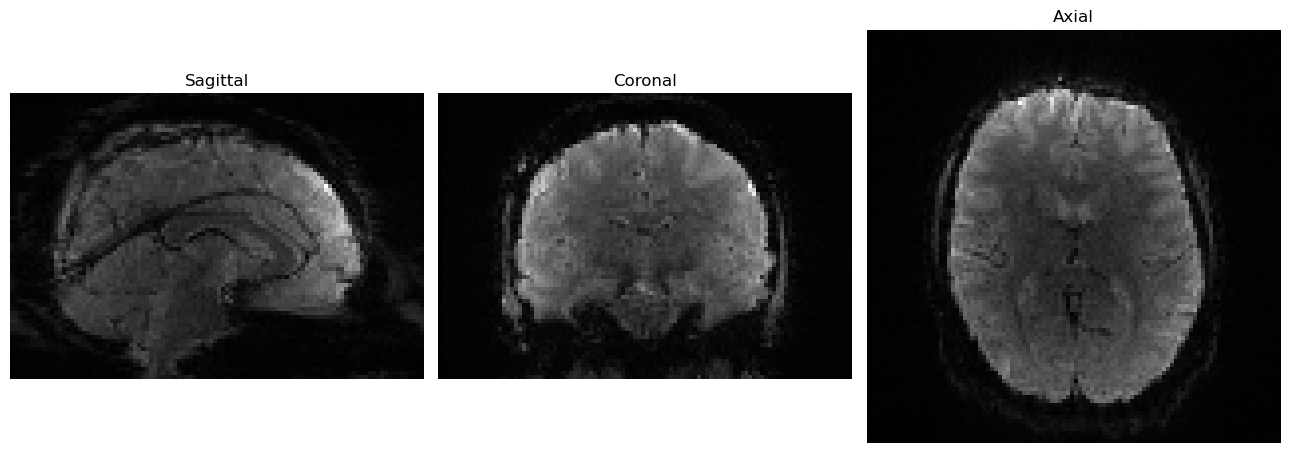

In [39]:
middle = [s // 2 for s in fmri_data.shape[:3]]

volume = fmri_data[:, :, :, 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

axes[0].imshow(
    volume[middle[0], :, :].T,
    cmap="gray",
    origin="lower"
)

axes[1].imshow(
    volume[:, middle[1], :].T,
    cmap="gray",
    origin="lower"
)

axes[2].imshow(
    volume[:, :, middle[2]].T,
    cmap="gray",
    origin="lower"
)

for ax, name in zip(
    axes, ["Sagittal", "Coronal", "Axial"]
):
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "brain_slices.png", dpi=300)
plt.show()

In [ ]:
global_signal = np.mean(
    fmri_data,
    axis=(0, 1, 2),
    dtype=np.float64
)

print("Signal length:", len(global_signal))
print("Signal mean:", np.mean(global_signal))
print("Signal standard deviation:", np.std(global_signal))

np.save(
    OUTPUT_DIR / "global_mean_bold_signal.npy",
    global_signal
)